# Eigensolvers

Four entry points in `qaravan.applications.algorithms`:

| function | takes | sectors it understands |
|---|---|---|
| `ground_state` | any qubit `Hamiltonian` | `fixed_particle_number`, or an explicit `sector` |
| `spectrum` | any qubit `Hamiltonian` | same, plus `num_eigenvalues` |
| `fermionic_ground_state` | `FermionicHamiltonian` + `FermionicEncoding` | above, plus `fixed_spin_numbers` |
| `fermionic_spectrum` | `FermionicHamiltonian` + `FermionicEncoding` | same, plus `num_eigenvalues` |

**Methods.** `"naive"` is dense `eigh`/`eigvalsh` — the whole spectrum, robust at any size.
`"naive_lanczos"` is `eigsh(k=num_eigenvalues)`; but still builds the dense $2^n \times 2^n$ matrix first. `"lanczos"` is reserved for the matrix-free solver and currently raises.

This notebook mostly tests if the solvers are choosing number and spin sectors correctly

In [12]:
import numpy as np
import matplotlib.pyplot as plt

from qaravan.applications.algorithms import (
    fermionic_ground_state,
    fermionic_spectrum,
    ground_state,
    spectrum,
)
from qaravan.core.fermions import FermionicEncoding, number
from qaravan.core.observables import NumberOperator
from qaravan.core.hamiltonians import (
    TFI,
    FermiHubbard1D,
    FermionicHamiltonian,
    Heisenberg1D,
)
from qaravan.plot import set_style

set_style()

## 1. Free fermions

At $U=0$ the Hubbard model is a pair of independent tight-binding chains with single-particle levels (OBC)

$$\varepsilon_k = -2t\cos\!\left(\frac{k\pi}{L+1}\right), \qquad k = 1,\dots,L,$$

and the ground energy in the $(N_\uparrow, N_\downarrow)$ sector is the sum of the $N_\uparrow$
lowest levels plus the $N_\downarrow$ lowest. 

In [3]:
def free_fermion_energy(num_sites, t, num_up, num_down):
    """Sum of occupied levels; open chain has eps_k = -2t cos(k pi/(L+1))."""
    levels = np.sort(-2 * t * np.cos(np.pi * np.arange(1, num_sites + 1) / (num_sites + 1)))
    return levels[:num_up].sum() + levels[:num_down].sum()


worst = 0.0
for num_sites in [2, 3, 4]:
    fh = FermiHubbard1D(num_fermionic_sites=num_sites, t=1.0, U=0.0, mu=0.0)
    encoding = FermionicEncoding("jordan_wigner", num_modes=2 * num_sites)
    for num_up in range(num_sites + 1):
        for num_down in range(num_sites + 1):
            got = fermionic_spectrum(
                fh, encoding, num_eigenvalues=1, fixed_spin_numbers=(num_up, num_down)
            )[0]
            want = free_fermion_energy(num_sites, 1.0, num_up, num_down)
            worst = max(worst, abs(got - want))

print(f"worst deviation over all 51 (L, N_up, N_down) combinations: {worst:.2e}")

worst deviation over all 51 (L, N_up, N_down) combinations: 3.55e-15


## 2. Verify sector selection by hand

The returned state should have zero amplitude on any basis state with the wrong occupation.
Check that directly from bitstrings, without trusting the solver's own masks. Note qubit $q$ is
character $q$ of the bitstring, i.e. **qubit 0 is the most significant bit** — that convention
is what the mask arithmetic has to respect.

In [7]:
fh = FermiHubbard1D(num_fermionic_sites=3, t=1.0, U=2.0, mu=0.0)
encoding = FermionicEncoding("jordan_wigner", num_modes=6)   # stacked: up = 0,1,2
sv = fermionic_ground_state(fh, encoding, fixed_spin_numbers=(2, 1))
amplitudes = sv.to_array()

leak, weight = 0.0, 0.0
for index in range(2**6):
    bits = format(index, "06b")
    num_up = sum(bits[q] == "1" for q in [0, 1, 2])
    num_down = sum(bits[q] == "1" for q in [3, 4, 5])
    if (num_up, num_down) == (2, 1):
        weight += abs(amplitudes[index]) ** 2
    else:
        leak = max(leak, abs(amplitudes[index]))

print(f"largest amplitude outside the (2,1) sector: {leak:.2e}")
print(f"probability inside the sector:              {weight:.12f}")

largest amplitude outside the (2,1) sector: 0.00e+00
probability inside the sector:              1.000000000000


In [10]:
up_qubits, down_qubits = encoding.spin_qubits()
print(f"total    <N>      = {sv.expectation(NumberOperator(6)).real:.10f}")
print(f"up       <N_up>   = {sv.expectation(NumberOperator(6, up_qubits)).real:.10f}")
print(f"down     <N_down> = {sv.expectation(NumberOperator(6, down_qubits)).real:.10f}")

total    <N>      = 3.0000000000
up       <N_up>   = 2.0000000000
down     <N_down> = 1.0000000000


## 3. Sector selection works even without spin-flip symmetry

The plain Hubbard model is spin-flip symmetric, so $(2,1)$ and $(1,2)$ are degenerate — adding a
field on the up modes only breaks that and allows us to test we are selecting sectors correctly

In the right panel the $(2,1)$ curve should sit *above* $(1,2)$ by roughly
$2\times 0.7 - 1\times 0.7 = 0.7$ — one extra up particle paying the field. 

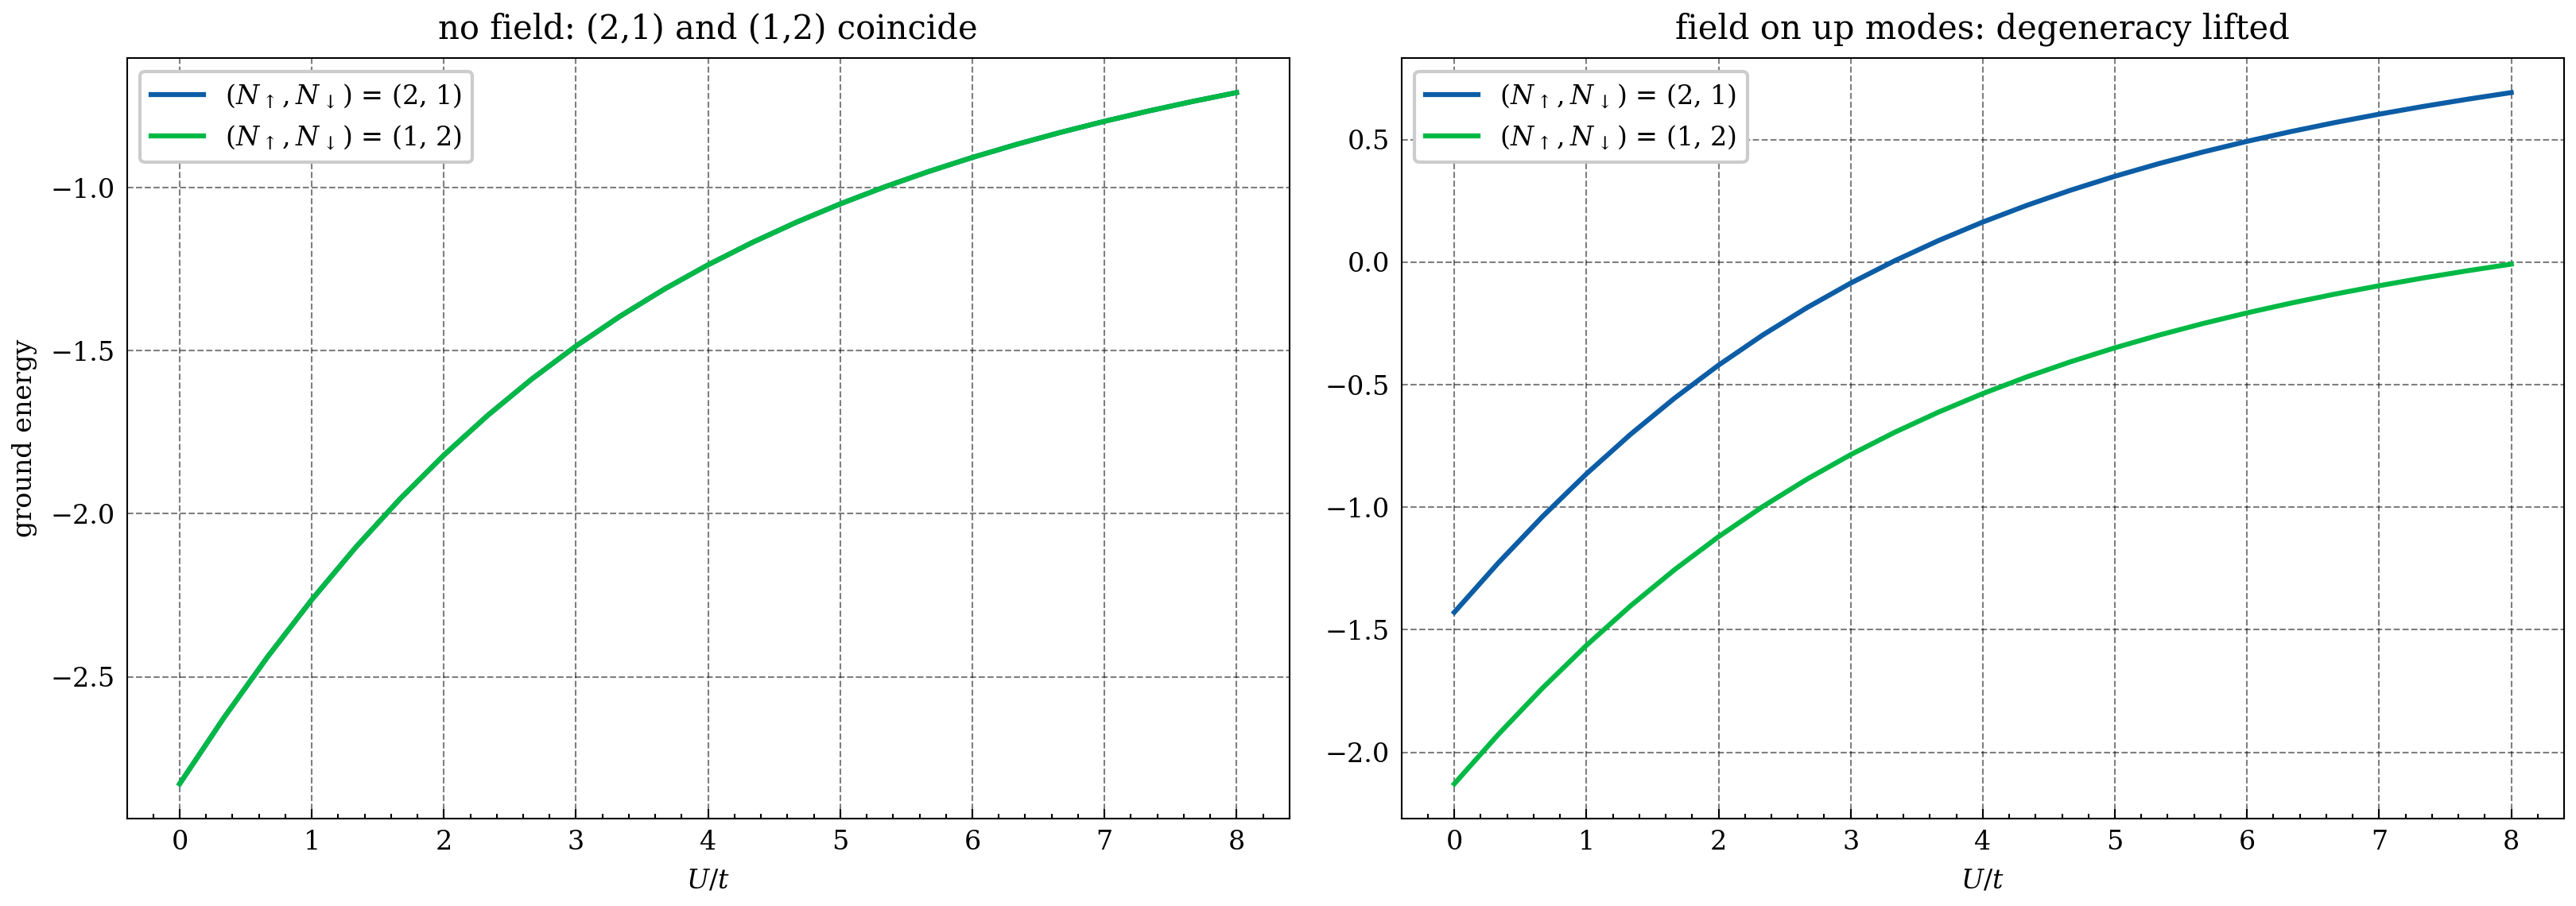

zero-field  |E(2,1) - E(1,2)| = 5.551115123125783e-16
with field  |E(2,1) - E(1,2)| = 0.7000000000000073


In [13]:
def zeeman_hubbard(num_sites, U, zeeman):
    """Hubbard plus a field on the up modes only, breaking (n_up, n_dn) <-> (n_dn, n_up)."""
    fh = FermiHubbard1D(num_fermionic_sites=num_sites, t=1.0, U=U)
    terms = list(fh.terms) + [zeeman * number(mode) for mode in range(num_sites)]
    return FermionicHamiltonian(terms, 2 * num_sites)


encoding = FermionicEncoding("jordan_wigner", num_modes=6)
u_values = np.linspace(0.0, 8.0, 25)
curves = {sector: [] for sector in [(2, 1), (1, 2)]}

for U in u_values:
    ham = zeeman_hubbard(3, U, zeeman=0.0)
    for sector in curves:
        curves[sector].append(
            fermionic_spectrum(ham, encoding, num_eigenvalues=1, fixed_spin_numbers=sector)[0]
        )

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for sector, values in curves.items():
    axes[0].plot(u_values, values, label=f"$(N_\\uparrow,N_\\downarrow)$ = {sector}")
axes[0].set_xlabel("$U/t$"); axes[0].set_ylabel("ground energy")
axes[0].set_title("no field: (2,1) and (1,2) coincide"); axes[0].legend()

split = {sector: [] for sector in [(2, 1), (1, 2)]}
for U in u_values:
    ham = zeeman_hubbard(3, U, zeeman=0.7)
    for sector in split:
        split[sector].append(
            fermionic_spectrum(ham, encoding, num_eigenvalues=1, fixed_spin_numbers=sector)[0]
        )
for sector, values in split.items():
    axes[1].plot(u_values, values, label=f"$(N_\\uparrow,N_\\downarrow)$ = {sector}")
axes[1].set_xlabel("$U/t$"); axes[1].set_title("field on up modes: degeneracy lifted"); axes[1].legend()
plt.tight_layout(); plt.show()

print("zero-field  |E(2,1) - E(1,2)| =", np.max(np.abs(np.array(curves[(2,1)]) - np.array(curves[(1,2)]))))
print("with field  |E(2,1) - E(1,2)| =", np.max(np.abs(np.array(split[(2,1)]) - np.array(split[(1,2)]))))

## 4. Spectrum gives lowest eigenvalues

`spectrum` with no `num_eigenvalues` returns the whole spectrum. An integer gives the lowest
$k$ levels, and `"naive_lanczos"` computes only those.

max |naive_lanczos - naive| over the lowest 8: 1.758593271006248e-13


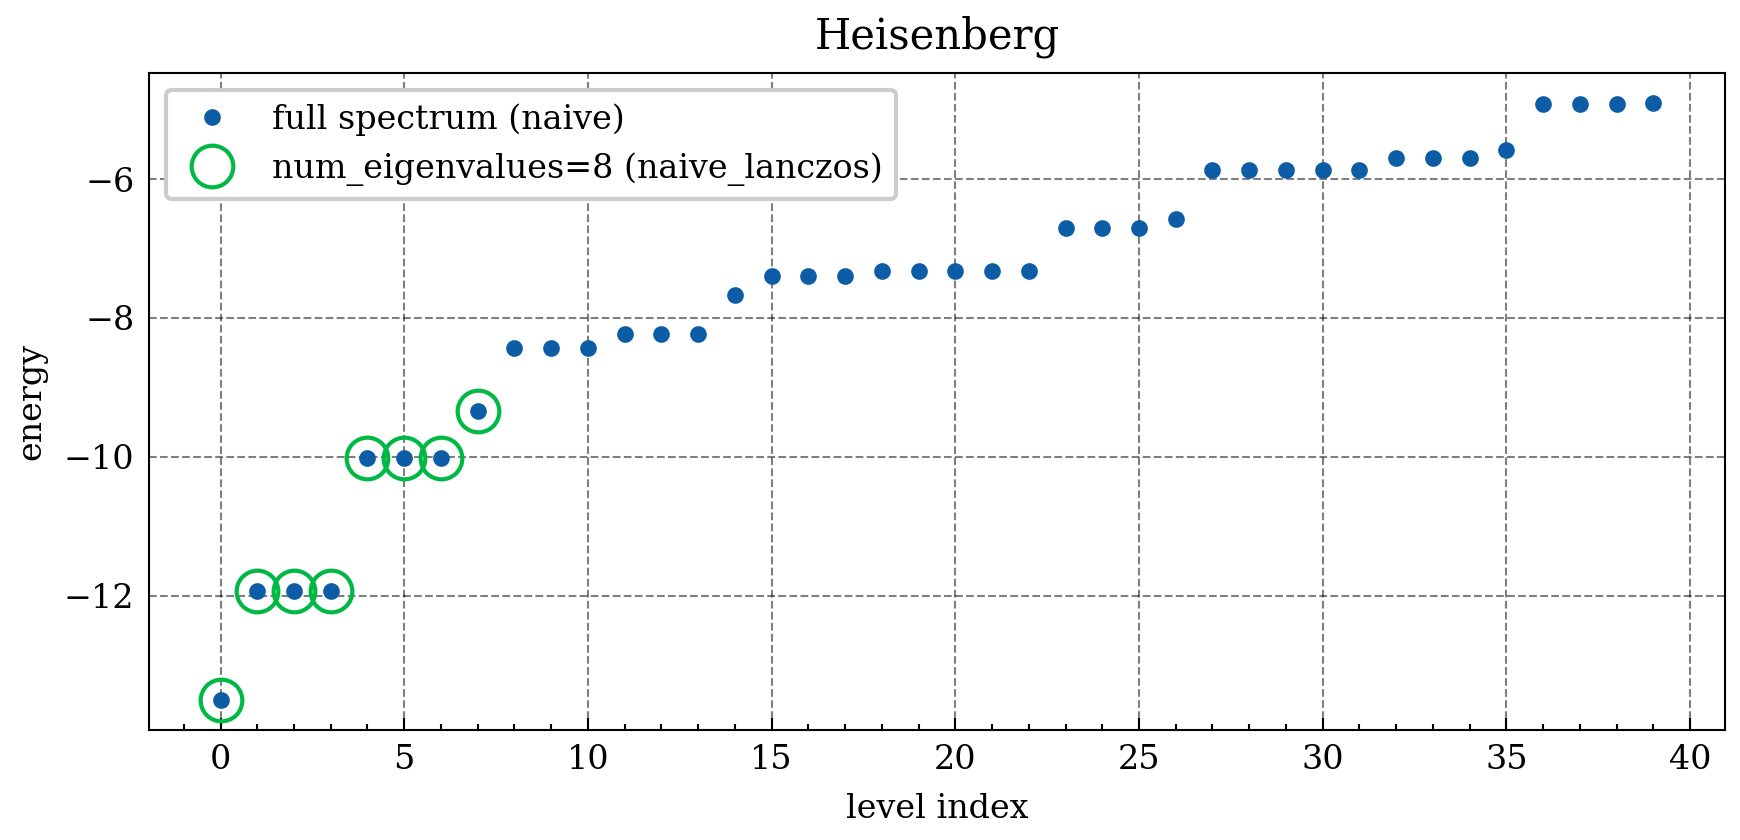

In [17]:
heis = Heisenberg1D(8, J=1.0, h=0.0)
full = spectrum(heis)
low = spectrum(heis, method="naive_lanczos", num_eigenvalues=8)

print("max |naive_lanczos - naive| over the lowest 8:", np.max(np.abs(low - full[:8])))

plt.figure(figsize=(6,3))
plt.plot(full[:40], ".", label="full spectrum (naive)")
plt.plot(low, "o", mfc="none", ms=10, label="num_eigenvalues=8 (naive_lanczos)")
plt.xlabel("level index"); plt.ylabel("energy")
plt.title("Heisenberg")
plt.legend()
plt.tight_layout(); plt.show()

## 5. Sector restriction is a real saving

Restricting to fixed particle number diagonalizes a $\binom{n}{k}$ block instead of the full
$2^n$ one.

In [18]:
from math import comb

fh = FermiHubbard1D(num_fermionic_sites=3, t=1.0, U=2.0)
encoding = FermionicEncoding("jordan_wigner", num_modes=6)
restricted = fermionic_spectrum(fh, encoding, fixed_particle_number=3)
print(f"full space 2^6 = 64,   half-filled block = {len(restricted)}  (expected {comb(6, 3)})")

# the sector's levels are a subset of the full spectrum
full = fermionic_spectrum(fh, encoding)
print("every sector level appears in the full spectrum:",
      all(np.min(np.abs(full - level)) < 1e-9 for level in restricted))

full space 2^6 = 64,   half-filled block = 20  (expected 20)
every sector level appears in the full spectrum: True
